In [4]:
# carregar a base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.cloud import bigquery
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_ID = "radar-economia-br"
client = bigquery.Client(project=PROJECT_ID, location="US")

df = client.query(f"""
    SELECT * FROM `{PROJECT_ID}.economia_br.vw_base_mensal` ORDER BY mes
""").to_dataframe()
df["mes"] = pd.to_datetime(df["mes"]).dt.tz_localize(None)
df = df.set_index("mes")

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})
df.tail(3)

/Users/vidigal/Documents/radar-economia-br/.venv/lib/python3.14/site-packages/google/cloud/bigquery/table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,ipca_mensal,ipca_12m,selic_media,dolar_medio,dolar_fim_mes,desemprego,ibc_br,dolar_var_pct,ibc_br_var_12m,juro_real
mes,,,,,,,,,,
2026-07-01,0.07,4.443025,14.250000,5.113948,5.0773,5.3,114.48992,-0.27,1.14,9.39
2026-08-01,-0.32,4.223453,14.040323,5.153162,5.1816,5.3,111.71919,0.77,1.21,9.42
2026-09-01,0.82,4.576120,13.883333,5.144724,5.1809,NaN,NaN,-0.16,NaN,8.90


In [ ]:
# criar as variáveis (feature engineering)
f = pd.DataFrame(index=df.index)

# Inflação passada
f["ipca"] = df["ipca_mensal"]
for l in [1, 2, 3, 6, 11]:
    f[f"ipca_lag{l}"] = df["ipca_mensal"].shift(l)
f["ipca_mm3"] = df["ipca_mensal"].rolling(3).mean()
f["ipca_mm12"] = df["ipca_mensal"].rolling(12).mean()
f["ipca_12m"] = df["ipca_12m"]

# Política monetária (efeito defasado, ~12 meses no passo 5)
f["selic"] = df["selic_media"]
f["selic_d3"] = df["selic_media"].diff(3)
f["selic_d12"] = df["selic_media"].diff(12)
f["selic_lag12"] = df["selic_media"].shift(12)
f["juro_real"] = df["juro_real"]

# Câmbio (lag 4 foi o único significativo no passo 5)
for l in range(0, 7):
    f[f"dolar_var_lag{l}"] = df["dolar_var_pct"].shift(l)

# Sazonalidade do mês que será previsto (t+1), em forma circular
mes_alvo = (df.index.month % 12) + 1
f["mes_sin"] = np.sin(2 * np.pi * mes_alvo / 12)
f["mes_cos"] = np.cos(2 * np.pi * mes_alvo / 12)

# Alvo: IPCA do mês seguinte
alvo = df["ipca_mensal"].shift(-1)

X_all = f.dropna()
X_futuro = X_all.iloc[[-1]]          # último mês: ainda não tem alvo, é o que vamos prever
X = X_all.iloc[:-1]
y = alvo.loc[X.index]

print("Observações para modelagem:", len(X))
print("Período:", X.index.min().date(), "até", X.index.max().date())
print("Mês usado para prever o futuro:", X_futuro.index[0].date())

Observações para modelagem: 188
Período: 2011-01-01 até 2026-08-01
Mês usado para prever o futuro: 2026-09-01


In [ ]:
# validação walk-forward
tscv = TimeSeriesSplit(n_splits=6, test_size=12)

modelos = {
    "Ridge": make_pipeline(
        StandardScaler(),
        RidgeCV(alphas=np.logspace(-2, 3, 30),
                cv=TimeSeriesSplit(n_splits=3),
                scoring="neg_mean_absolute_error"),
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=3, max_features=0.5,
        random_state=42, n_jobs=-1,
    ),
}

partes = []
for treino, teste in tscv.split(X):
    X_tr, X_te = X.iloc[treino], X.iloc[teste]
    y_tr, y_te = y.iloc[treino], y.iloc[teste]

    bloco = pd.DataFrame({"real": y_te})

    # Baselines
    bloco["Baseline: mês anterior"] = X_te["ipca"]
    bloco["Baseline: mesmo mês do ano anterior"] = X_te["ipca_lag11"]
    bloco["Baseline: média 12 meses"] = X_te["ipca_mm12"]

    # Modelos
    for nome, modelo in modelos.items():
        modelo.fit(X_tr, y_tr)
        bloco[nome] = modelo.predict(X_te)

    partes.append(bloco)

previsoes = pd.concat(partes)
previsoes.index = previsoes.index + pd.offsets.MonthBegin(1)   # índice = mês-alvo
previsoes.index.name = "mes"
print("Período de teste:", previsoes.index.min().date(), "até", previsoes.index.max().date())

Período de teste: 2020-10-01 até 2026-09-01


In [ ]:
# comparar os modelos
def metricas(previsoes):
    linhas = []
    for col in previsoes.columns.drop("real"):
        erro = previsoes["real"] - previsoes[col]
        linhas.append({
            "modelo": col,
            "MAE (p.p.)": erro.abs().mean(),
            "RMSE (p.p.)": np.sqrt((erro ** 2).mean()),
        })
    return pd.DataFrame(linhas).sort_values("MAE (p.p.)").round(3).reset_index(drop=True)

tabela = metricas(previsoes)
tabela

,modelo,MAE (p.p.),RMSE (p.p.)
0,Random Forest,0.285,0.378
1,Ridge,0.289,0.377
2,Baseline: média 12 meses,0.304,0.422
3,Baseline: mês anterior,0.323,0.432
4,Baseline: mesmo mês do ano anterior,0.394,0.518


In [15]:
# Teste excluindo o período de pandemia
sem_covid = previsoes[~previsoes.index.to_series().between("2020-03-01", "2022-12-31")]
print("Teste excluindo mar/2020 a dez/2022:", len(sem_covid), "meses")
metricas(sem_covid)

Teste excluindo mar/2020 a dez/2022: 45 meses


,modelo,MAE (p.p.),RMSE (p.p.)
0,Random Forest,0.216,0.287
1,Ridge,0.217,0.280
2,Baseline: média 12 meses,0.230,0.298
3,Baseline: mês anterior,0.273,0.374
4,Baseline: mesmo mês do ano anterior,0.280,0.352


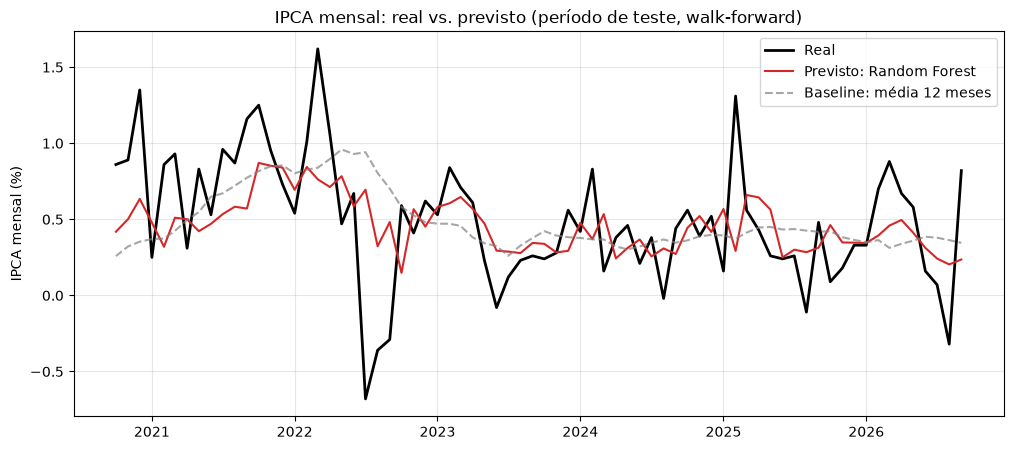

In [16]:
# gráfico real vs. previsto
melhor = tabela.loc[~tabela["modelo"].str.startswith("Baseline"), "modelo"].iloc[0]

fig, ax = plt.subplots()
ax.plot(previsoes.index, previsoes["real"], label="Real", color="black", lw=2)
ax.plot(previsoes.index, previsoes[melhor], label=f"Previsto: {melhor}", color="tab:red")
ax.plot(previsoes.index, previsoes["Baseline: média 12 meses"],
        label="Baseline: média 12 meses", color="gray", ls="--", alpha=0.7)
ax.set_title("IPCA mensal: real vs. previsto (período de teste, walk-forward)")
ax.set_ylabel("IPCA mensal (%)")
ax.legend()
plt.savefig("../imagens/07_previsto_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

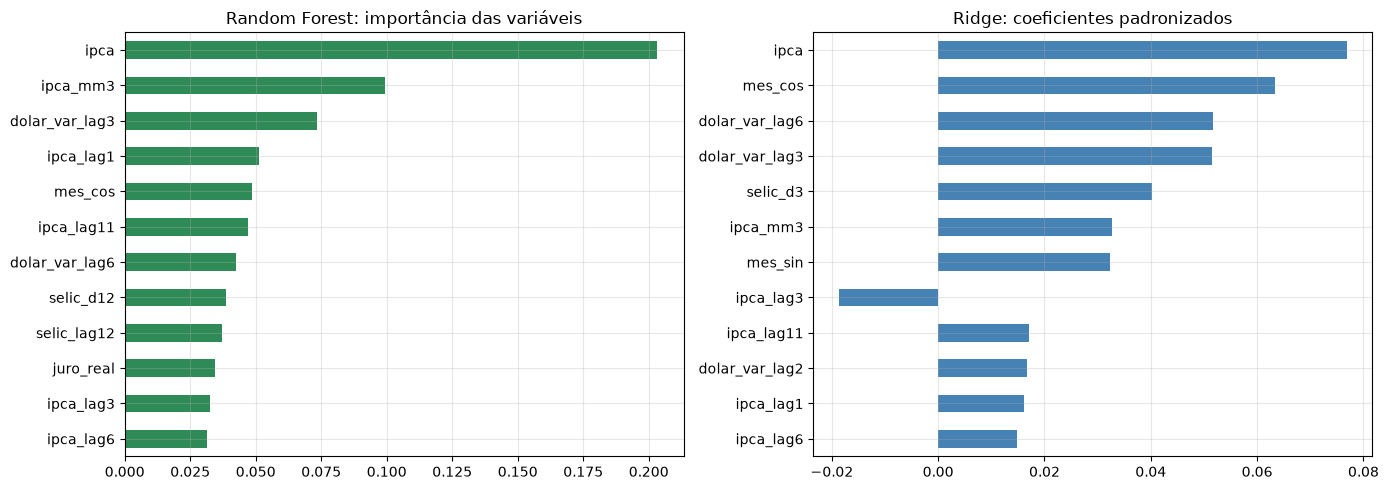

Alpha escolhido no Ridge: 62.10169418915616


In [17]:
# Treina com todos os dados para interpretar
rf = modelos["Random Forest"].fit(X, y)
ridge = modelos["Ridge"].fit(X, y)

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(12)
coef = pd.Series(ridge[-1].coef_, index=X.columns)
coef = coef.reindex(coef.abs().sort_values().tail(12).index)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
imp.plot(kind="barh", ax=axes[0], color="seagreen", title="Random Forest: importância das variáveis")
coef.plot(kind="barh", ax=axes[1], color="steelblue", title="Ridge: coeficientes padronizados")
plt.tight_layout()
plt.savefig("../imagens/08_importancia_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

print("Alpha escolhido no Ridge:", ridge[-1].alpha_)

In [18]:
# previsão para o próximo mês com intervalo
erros = previsoes["real"] - previsoes[melhor]
q05, q95 = erros.quantile([0.05, 0.95])

modelo_final = modelos[melhor].fit(X, y)
ponto = float(modelo_final.predict(X_futuro)[0])
mes_prev = (X_futuro.index[0] + pd.offsets.MonthBegin(1)).date()

print(f"Previsão do IPCA de {mes_prev} ({melhor}): {ponto:.2f}%")
print(f"Intervalo empírico 90%: {ponto + q05:.2f}% a {ponto + q95:.2f}%")

Previsão do IPCA de 2026-10-01 (Random Forest): 0.53%
Intervalo empírico 90%: 0.07% a 1.12%


In [19]:
# salvar as previsões no BigQuery
saida = previsoes.reset_index().rename(columns={"index": "mes"})
saida.columns = [c.replace(":", "").replace(" ", "_").replace("í", "i").replace("é", "e").replace("ê", "e") for c in saida.columns]
saida["mes"] = pd.to_datetime(saida["mes"])

job = client.load_table_from_dataframe(
    saida, f"{PROJECT_ID}.economia_br.previsoes_ipca_teste",
    job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"),
)
job.result()
print("Linhas salvas:", client.get_table(f"{PROJECT_ID}.economia_br.previsoes_ipca_teste").num_rows)

previsoes.to_csv("../notebooks/data/processed/previsoes_teste.csv")

/Users/vidigal/Documents/radar-economia-br/.venv/lib/python3.14/site-packages/google/cloud/bigquery/_pandas_helpers.py:486: FutureWarning: Loading pandas DataFrame into BigQuery will require pandas-gbq package version 0.26.1 or greater in the future. Tried to import pandas-gbq and got: No module named 'pandas_gbq'
  warnings.warn(


Linhas salvas: 72


In [20]:
prev_futura = pd.DataFrame({
    "mes_alvo": [pd.Timestamp(mes_prev)],
    "modelo": [melhor],
    "previsao": [ponto],
    "limite_inferior_90": [ponto + q05],
    "limite_superior_90": [ponto + q95],
    "data_geracao": [pd.Timestamp.today().normalize()],
})

client.load_table_from_dataframe(
    prev_futura, f"{PROJECT_ID}.economia_br.previsoes_ipca_futuro",
    job_config=bigquery.LoadJobConfig(write_disposition="WRITE_APPEND"),
).result()

print(client.get_table(f"{PROJECT_ID}.economia_br.previsoes_ipca_futuro").num_rows, "linha(s)")

/Users/vidigal/Documents/radar-economia-br/.venv/lib/python3.14/site-packages/google/cloud/bigquery/_pandas_helpers.py:486: FutureWarning: Loading pandas DataFrame into BigQuery will require pandas-gbq package version 0.26.1 or greater in the future. Tried to import pandas-gbq and got: No module named 'pandas_gbq'
  warnings.warn(


1 linha(s)


In [7]:
print("Meses juro real < 0:", int((df["juro_real"] < 0).sum()))
print("Máx. juro real:", df["juro_real"].idxmax().date(), round(df["juro_real"].max(), 2))
print("Último IPCA mensal:", df["ipca_mensal"].dropna().iloc[-1], df["ipca_mensal"].dropna().index[-1].date())
print("Último IPCA 12m:", round(df["ipca_12m"].dropna().iloc[-1], 2))
print("Último desemprego:", df["desemprego"].dropna().iloc[-1], df["desemprego"].dropna().index[-1].date())
print("Previsão futura:", round(ponto, 2), round(ponto + q05, 2), round(ponto + q95, 2))

Meses juro real < 0: 21
Máx. juro real: 2026-02-01 10.78
Último IPCA mensal: 0.82 2026-09-01
Último IPCA 12m: 4.58
Último desemprego: 5.3 2026-08-01


NameError: name 'ponto' is not defined